https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data?select=data_description.txt

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv("train.csv") # coś się zepsuło, gdy próbowałam dać nazwę df
print(train.shape)
train.head(5)

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# **Pytania naprowadzające**

* Jaka jest zmienna docelowa (ang. target variable), którą chcemy przewidywać? Cena sprzedaży domu - SalePrice

* Jakie rodzaje zmiennych są w zbiorze (liczbowe, kategoryczne, tekstowe)? Liczbowe np.: LotFrontage float64, LotArea int64, kategoryczne np.: MSZoning object, nie mamy tu typowych zmiennych tekstowych, teksty, które widzimi są kategoriami

# **Zadania**

In [3]:
pd.set_option('display.max_columns', None) # zmienim by w describe zobaczyć wszystkie kolumny
pd.set_option('display.max_rows', 100) # zmianiam maks ustawienia wyświetlania by móc zobaczyć wszystkie kolumny w bazie, czyli wypisane wiersze
# Wyświetl podstawowe statystyki opisowe (df.describe()).
display(train.describe())
# Sprawdź typy danych wszystkich kolumn (df.dtypes).
print(train.dtypes)
# znalezione typy kolum to: int64 object float64

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1         int64
BsmtFinType2      object
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating           object


# **Sprawdź braki danych — i ustal, co oznaczają (data_description.txt).**


# **Sprawdzenie oznaczeń NA i None w opisie zbioru**

Allay, NA - No alley access

MasVnrType, None - None

BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, NA - No Basement

FireplaceQu NA - No Fireplace

GarageType, GarageFinish, GarageQual, GarageCond, NA - No Garage

PoolQC, NA - No Pool

Fence, NA - No Fence

MiscFeature, NA - None


Oznaczenia NA i None w powyżej wymienionych kolumnach oznaczają nie brak danych tylko brak danego wyposażenia, zalety domu

W przypadku piwnicy i garażu, mają one wiele kolumn, w których NA w jednej z nich powinno sprawić, że pozostałe kolumny dotyczące ich kategoryzacji, również powinny mieć wartość NA




In [4]:
# # potencjalne czyszczenie na przyszłość
# kolumny_z_brakami_jako_brak_cechy = [
#     "Alley",
#     "MasVnrType",
#     "BsmtQual",
#     "BsmtCond",
#     "BsmtExposure",
#     "BsmtFinType1",
#     "BsmtFinType2",
#     "FireplaceQu",
#     "GarageType",
#     "GarageFinish",
#     "GarageQual",
#     "GarageCond",
#     "PoolQC",
#     "Fence",
#     "MiscFeature",
# ]

# for kol in kolumny_z_brakami_jako_brak_cechy:
#   if kol in train.columns:
#     train[kol] = train[kol].fillna("None")

# **Wykresy**

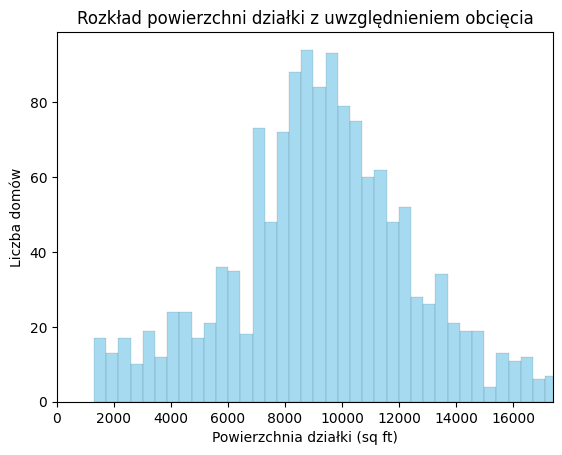

In [19]:
# Jak rozkładają się wartości jednej zmiennej liczbowej? histplot, kdeplot, ecdfplot
# Rozkład wielkości działki, ucięte do najczęściej występujących wartości
granica_lot_area = train["LotArea"].quantile(0.95)
sns.histplot(data=train, x="LotArea", bins=500, color="skyblue")
plt.xlim(0, granica_lot_area)

plt.title("Rozkład powierzchni działki z uwzględnieniem obcięcia")
plt.xlabel("Powierzchnia działki (sq ft)")
plt.ylabel("Liczba domów")
plt.show()


/tmp/ipykernel_34655/2584638042.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x="Foundation", y="YearBuilt", palette="Set2")


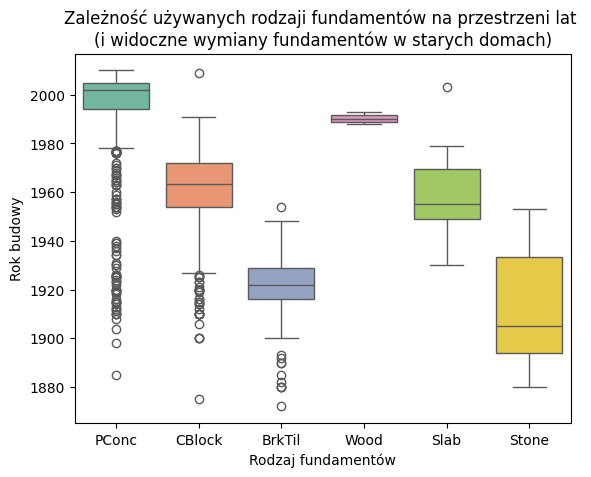

In [6]:
# Czym różnią się grupy? boxplot, violinplot
# zmiana typów fundamatów przez lata
sns.boxplot(data=train, x="Foundation", y="YearBuilt", palette="Set2")

plt.title("Zależność używanych rodzaji fundamentów na przestrzeni lat \n(i widoczne wymiany fundamentów w starych domach)")
plt.xlabel("Rodzaj fundamentów")
plt.ylabel("Rok budowy")
plt.show()

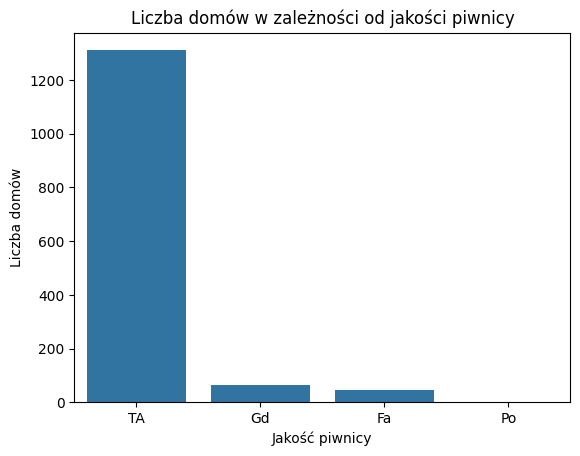

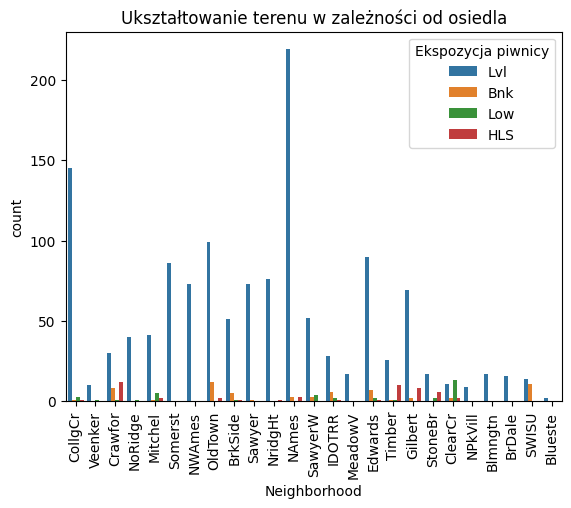

In [7]:
# Ile jest obserwacji w każdej kategorii? countplot, barplot
# liczba piwnic pod względem jakości
sns.countplot(data=train, x="BsmtCond")
plt.title("Liczba domów w zależności od jakości piwnicy")
plt.xlabel("Jakość piwnicy")
plt.ylabel("Liczba domów")
plt.show()

# ukształtowanie terenu w zależności od osiedla
sns.countplot(data=train, x="Neighborhood", hue="LandContour")
plt.title("Ukształtowanie terenu w zależności od osiedla")
plt.xticks(rotation=90)
plt.legend(title="Ekspozycja piwnicy")
plt.show()

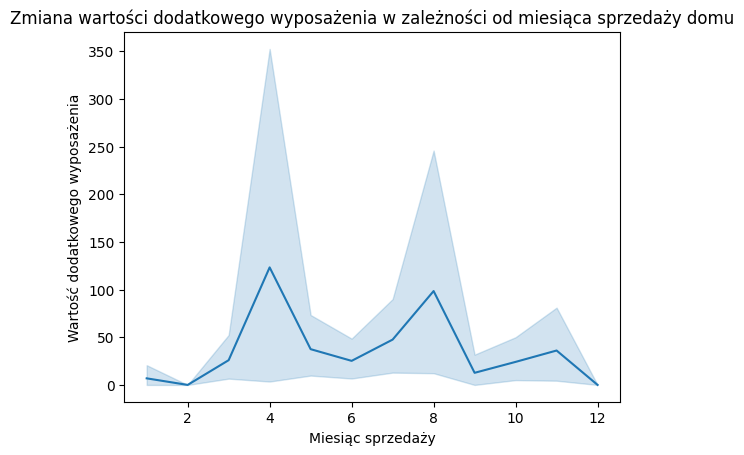

In [8]:
# Jak coś zmienia się w czasie? lineplot
# jak w ciągu miesięcy rosną na wartości dodatkowe wyposażenia
sns.lineplot(data=train, x="MoSold", y="MiscVal")
plt.title("Zmiana wartości dodatkowego wyposażenia w zależności od miesiąca sprzedaży domu")
plt.xlabel("Miesiąc sprzedaży")
plt.ylabel("Wartość dodatkowego wyposażenia")
plt.show()
# myślałam, że skoro dodatkowe wyposażenie jest zwykle w luksusowych domach i jest ono na zewnątrz
# to potencjalni kupujący decydowali, by się je kupować w lecie, by z niego móc od razu korzystać
# ale widzę, że nie ma tu takiego trendu, a dodatkowe wyposażenie nie ma większego wpływu na czas sprzedaży


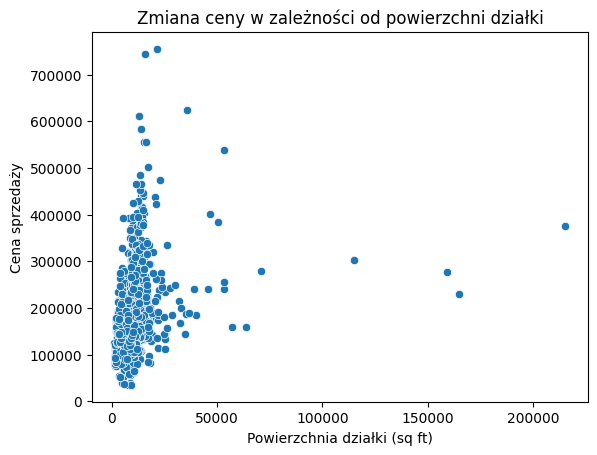

In [9]:
# Czy dwie zmienne liczbowe są powiązane? scatterplot
# wielkość działki a cena
sns.scatterplot(data=train, x="LotArea", y="SalePrice")
plt.title("Zmiana ceny w zależności od powierzchni działki")
plt.xlabel("Powierzchnia działki (sq ft)")
plt.ylabel("Cena sprzedaży")
plt.show()


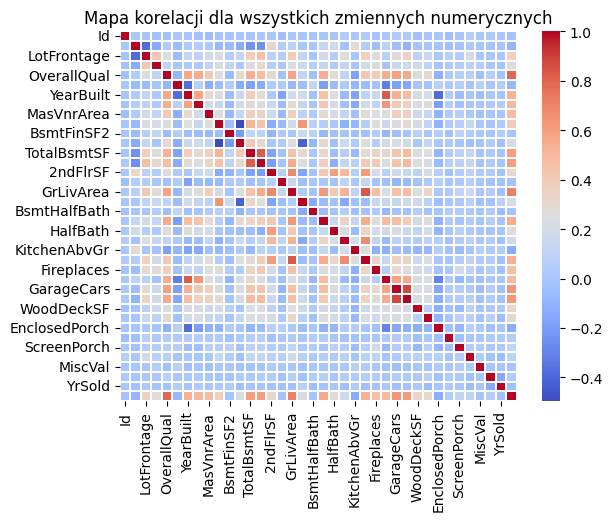

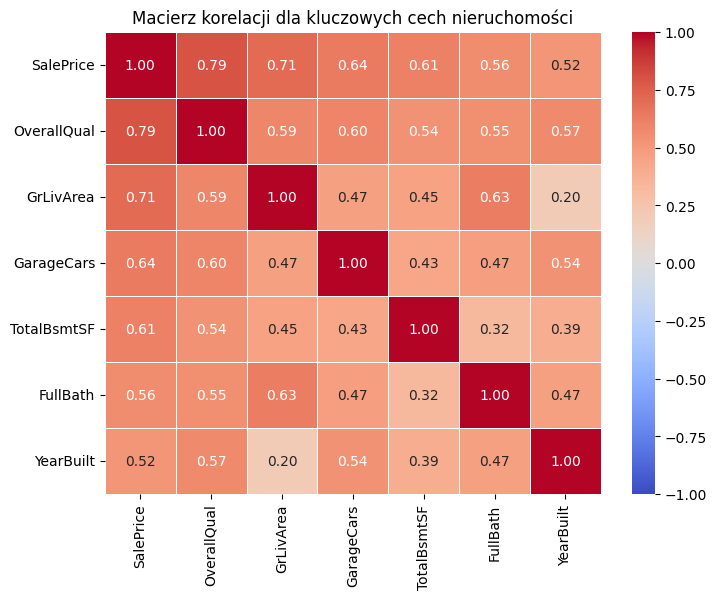

In [10]:
# Jak powiązanych jest wiele zmiennych naraz? heatmap, pairplot
corr_matrix = train.corr(numeric_only=True)
# sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
# mapa korelacji bez liczb by nie było szumu
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=False,  # Brak liczb, żeby nie tworzyć szumu – patrzymy na kolory
    linewidths=0.1,
)
plt.title("Mapa korelacji dla wszystkich zmiennych numerycznych")
plt.show()

# wersja parę kolumn, ale za to z liczbami
kluczowe_kolumny = [
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "FullBath",
    "YearBuilt"
]

corr_subset = train[kluczowe_kolumny].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_subset,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title("Macierz korelacji dla kluczowych cech nieruchomości")
plt.show()

# **Analiza zmiennej docelowej**

# **Pytania**
* Jaki jest rozkład cen?
  * Rozkład jest prawostronnie skośny, bo średnia jest większa od mediany i wartości mają duży ogon w prawo
* Czy są wartości odstające?
  * Tak
* Jaka jest średnia i mediana ceny?
  * Średnia: 180921.195890
  * Mediana: 163000.0  
* Czy ceny mają rozkład normalny?
(wskazówka: czy histogram jest
symetryczny?)
  * Nie histogram nie jest symetryczny


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


Średnia: 180921.19589041095
Mediana: 163000.0


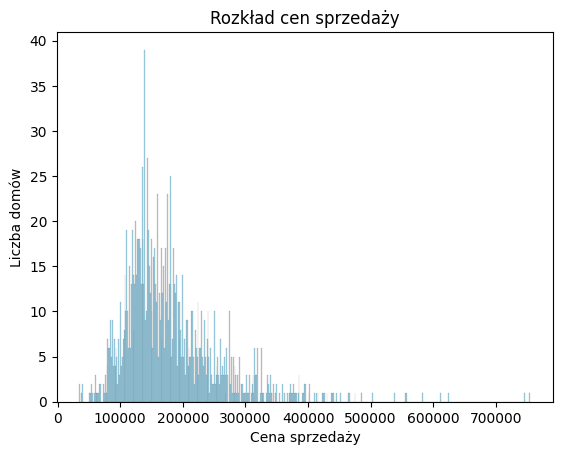

In [11]:
display(train.SalePrice.describe())
print(f"Średnia: {train.SalePrice.mean()}")
print(f"Mediana: {train.SalePrice.median()}")

sns.histplot(data=train, x="SalePrice", bins=500, color="skyblue")
plt.title("Rozkład cen sprzedaży")
plt.xlabel("Cena sprzedaży")
plt.ylabel("Liczba domów")
plt.show()


# **Zadania**
* Histogram cen: poeksperymentuj z liczbą przedziałów (bins = 10, 30, 50). Czy rozkład jest skośny?
  * Tak rozkład jest prawoskośny
* Wykres pudełkowy cen: czy widzisz
wartości odstające? Co mogą oznaczać
bardzo drogie domy?
  * Tak są wartości odstające
  * Bardzo drogie domy mogą być bardzo nowoczesne/ bardzo duże/ mieć drogie wyposażenie / mieć duże działki
* Policz: min, max, średnią, medianę, Q1, Q3, IQR.
  * Min: 34900
  * Max: 755000
  * Średnia: 180921.19589041095
  * Mediana: 163000.0
  * Q1: 129975.0
  * Q3: 214000.0
  * IQR: 84025.0


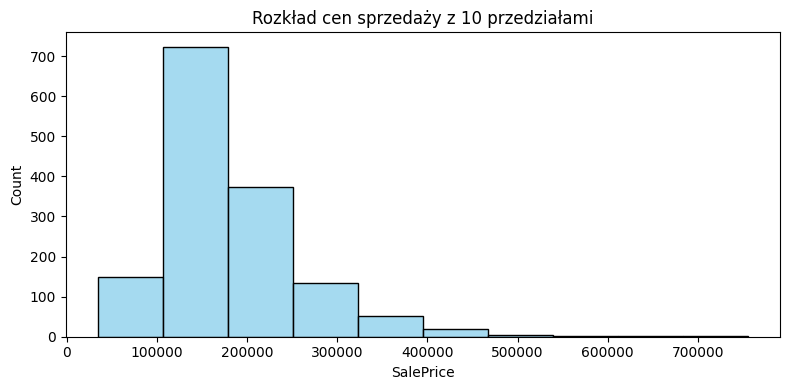

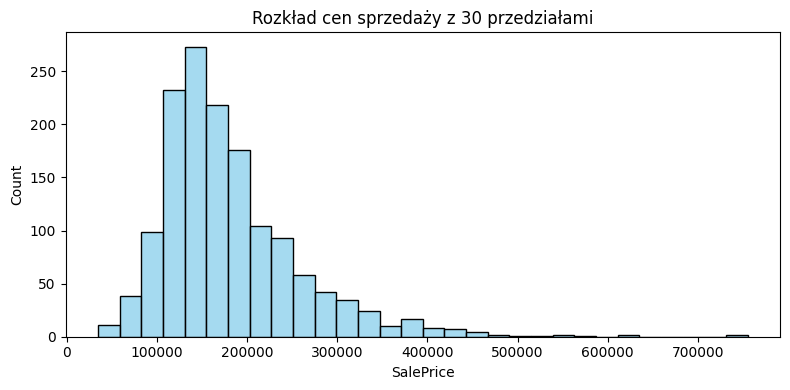

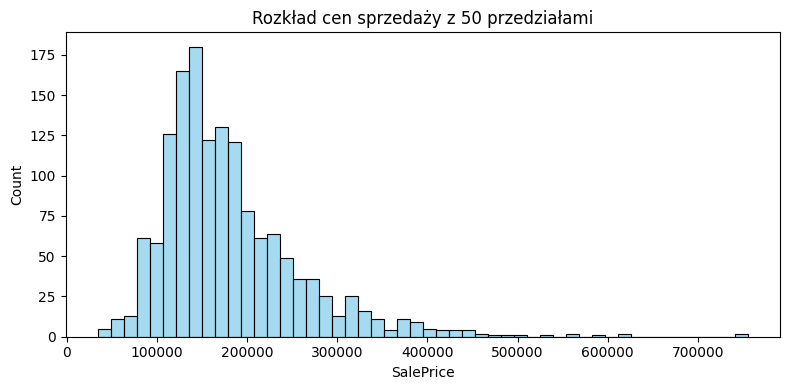

In [12]:
bins = [10, 30, 50]
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# for i, bin_val in enumerate(bins):
#   sns.histplot(
#       data=train,
#       x="SalePrice",
#       bins=bin_val,
#       color="skyblue",
#       kde=True,
#       ax=axes[i],
#   )
#   axes[i].set_title(f"Rozkład cen sprzedaży z {bin_val} przedziałami")
# plt.tight_layout()
# plt.show()

for bin in bins:
    plt.figure(figsize=(8,4))
    sns.histplot(data=train, x="SalePrice", bins=bin, color="skyblue")
    plt.title(f"Rozkład cen sprzedaży z {bin} przedziałami")
    plt.tight_layout()
    plt.show()


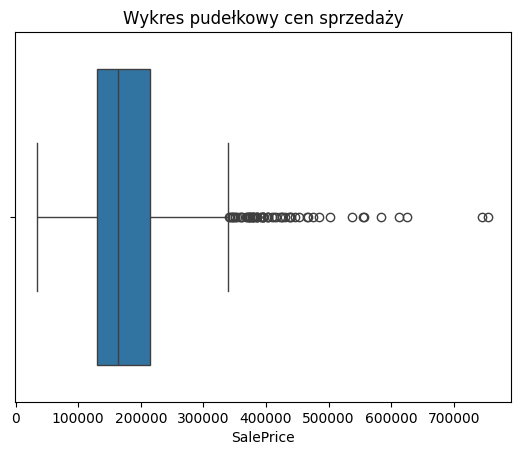

In [13]:
sns.boxplot(data=train, x="SalePrice")
plt.title("Wykres pudełkowy cen sprzedaży")
plt.show()



In [14]:
print(f"Min: {train.SalePrice.min()}")
print(f"Max: {train.SalePrice.max()}")
print(f"Średnia: {train.SalePrice.mean()}")
print(f"Mediana: {train.SalePrice.median()}")

q1 = train["SalePrice"].quantile(0.25)
# q3 = train["SalePrice"].quantile(0.75)
q3 = train.SalePrice.quantile(0.75) # to samo co ^

iqr = q3 - q1
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")


Min: 34900
Max: 755000
Średnia: 180921.19589041095
Mediana: 163000.0
Q1: 129975.0
Q3: 214000.0
IQR: 84025.0


# **Co wpływa na cenę domu?**

# **Hipoteza do sprawdzenia: „Większe domy są droższe”.**
* Znajdź zmienne związane z powierzchnią (wskazówka: szukaj „Area” i „SF” w nazwach
kolumn).
  * LotArea, MasVnrArea, GrLivArea, GarageArea, PoolArea
  * BsmtFinSF1, BsmtFinSF2, BsmtUnfSF < są zawarte w TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, WoodDeckSF, OpenPorchSF
  * EnclosedPorch, 3SsnPorch, ScreenPorch mają area w opisie

* Narysuj wykres punktowy: powierzchnia mieszkalna vs cena.
  * Czy zależność jest wyraźna? Czy jest liniowa?
    * Tak widzimy wyraźną zależność liniową
  * Czy są dziwne obserwacje? Kim one są?
    * Tak mamy parę wyjątków od ogólnej liniowości, które mogą mieć np.: drogie dodatkowe wyposażenie, bardzo dużą działkę
  * Dla wariantu dodania powierzchni piwnicy, zależność liniowa jest, wciąż widoczna, ale jest teraz tak jakby bardziej szersza, przesunęła się w prawą stronę i ma mniejszy kąt nachylenia, a niektóre odstające punkty podpięły się pod zależność liniową, ze względu na jej niższy kąt. Jeżeli faktycznie mam rację w interpretowaniu opisów kolumn, to myślę, że drugi wykres lepiej oddaje zależność cena za powierzchnię mieszkalną


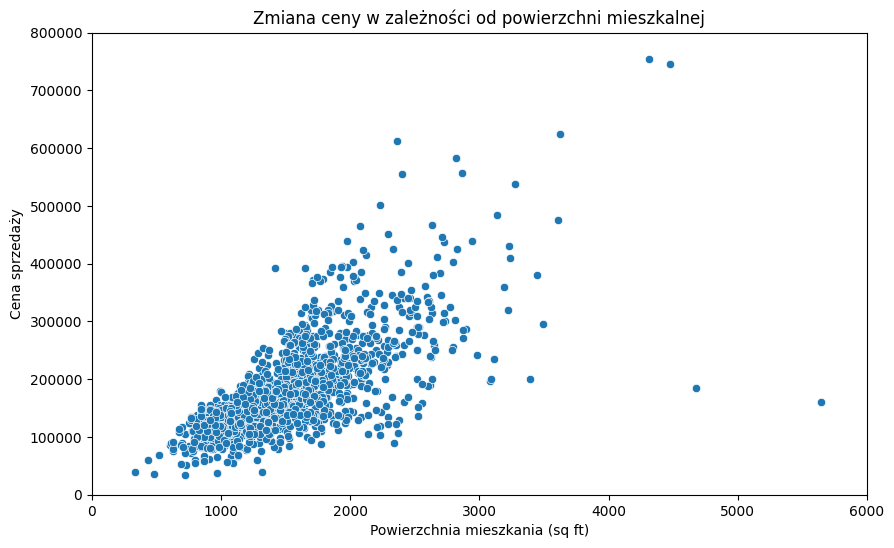

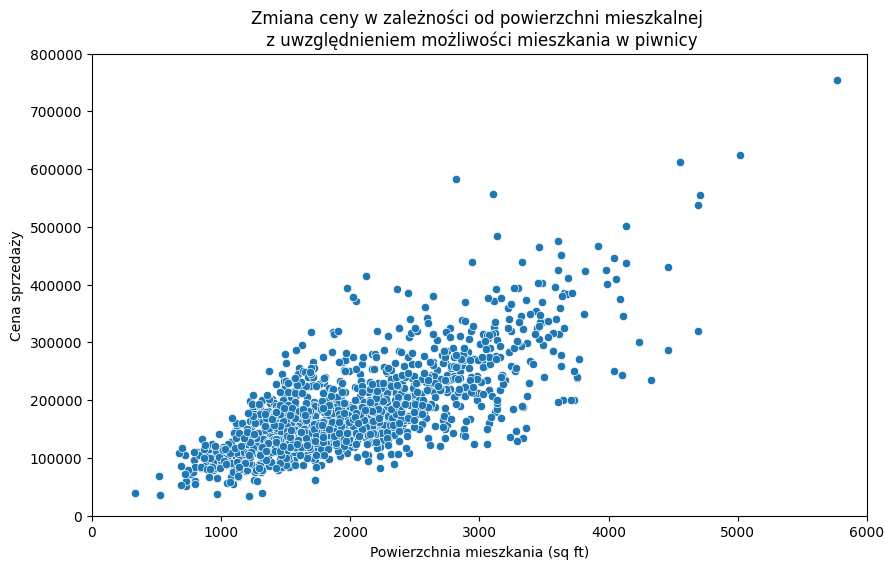

In [15]:
wspolny_zakres_x = (0, 6000)
wspolny_zakres_y = (0, 800000)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice")
plt.xlim(wspolny_zakres_x)
plt.ylim(wspolny_zakres_y)
plt.xticks(np.arange(0, 6001, 1000))
plt.title("Zmiana ceny w zależności od powierzchni mieszkalnej")
plt.xlabel("Powierzchnia mieszkania (sq ft)")
plt.ylabel("Cena sprzedaży")
plt.show()


# wersja z dodaniem powierzchni piwnicy, ponieważ kolumny v
# BsmtFullBath: Basement full bathrooms
# BsmtHalfBath: Basement half bathrooms
# sugerują, że jest zdolność mieszkania w piwnicy
# i wiem, że takie zachowanie nie jest niecodzienne w usa

train["TotalLivingArea"] = (
    train["GrLivArea"]
    + train["BsmtFinSF1"].fillna(0)
    + train["BsmtFinSF2"].fillna(0)
)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x="TotalLivingArea", y="SalePrice")
plt.xlim(wspolny_zakres_x)
plt.ylim(wspolny_zakres_y)
plt.xticks(np.arange(0, 6001, 1000))
plt.title("Zmiana ceny w zależności od powierzchni mieszkalnej \n z uwzględnieniem możliwości mieszkania w piwnicy")
plt.xlabel("Powierzchnia mieszkania (sq ft)")
plt.ylabel("Cena sprzedaży")
plt.show()

# **Dodatkowo**
* Czy powierzchnia działki (LotArea) ma taki sam wpływ jak powierzchnia domu?
  * Zdecydowanie nie, powierzchnia działki jest zwykle w bardzo małym przedziale od 0 do 25000 (na oko), a ceny zmieniają się diametralnie
* Narysuj wykresy punktowe dla 2–3 rodzajów powierzchni — która ma najsilniejszy związek z ceną?
  * Wybrałam kolumny: GrLivArea, LotArea i sumę wielkości piwnicy na podstawie kolumn BsmtFinSF1 i BsmtFinSF2, ponieważ pozostałe kolumny dotyczące powierzchni, są zawarte w tych ogólnych kolumnach, albo dotyczą nieczęstych dodatków do domu jak garaż, basen, taras np. GarageArea, PoolArea, LowQualFinSF, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch
  * Najsilniejszy związek z ceną ma powierzchnia mieszkania. Wykazuje największą zależność liniową
  * Dużą zależność liniową pokazuje też piwnica, ale bardzo duża część domów jej wogóle nie posiada, przez co mamy duży odsetek mieszkań niebiorących udział w liniowości i tym samym zaburzenie wpływu piwnicy na cenę
  * I jak już wyżej wspomniałam, powierzchnia działki nie wpływa znacząco na cene


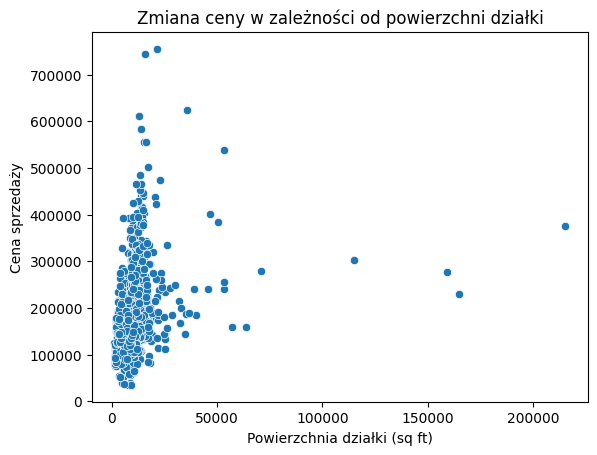

In [16]:
# już zrobiłam taki wykres, ale powtórzę dla widoczności
sns.scatterplot(data=train, x="LotArea", y="SalePrice")
plt.title("Zmiana ceny w zależności od powierzchni działki")
plt.xlabel("Powierzchnia działki (sq ft)")
plt.ylabel("Cena sprzedaży")
plt.show()

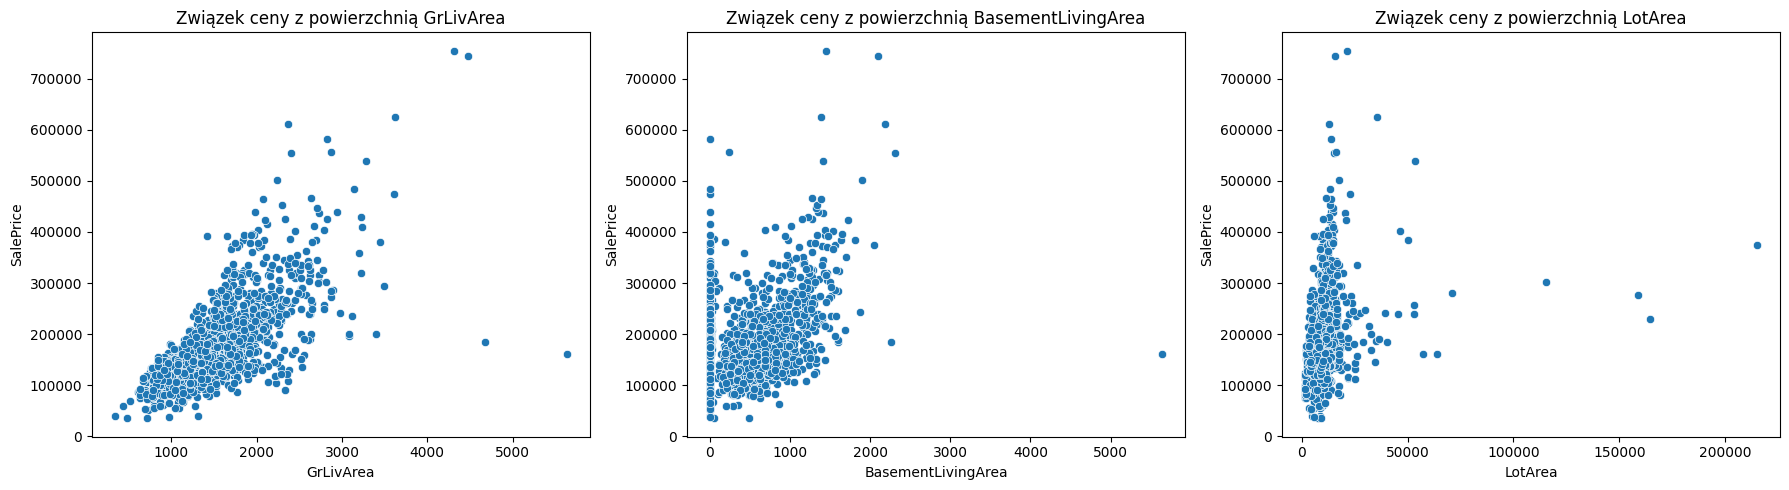

In [17]:
train["BasementLivingArea"] = (
    train["BsmtFinSF1"].fillna(0)
    + train["BsmtFinSF2"].fillna(0)
)

kolumny_do_sprawdzenia = [
        "GrLivArea",
        "BasementLivingArea",
        "LotArea"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, kol in enumerate(kolumny_do_sprawdzenia):
  sns.scatterplot(data=train, x=kol, y="SalePrice", ax=axes[i])
  axes[i].set_title(f"Związek ceny z powierzchnią {kol}")
plt.tight_layout()
plt.show()
